# Random Forest Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md).
Every lab is **self-contained**: a short goal, the code, the picture/numbers, and a
**"How to read this"** box that tells you what you should notice.

**How to use it**

1. Run the first code cell (imports). After that you can run any lab in order (`Shift + Enter` cell by cell),
   or `Kernel → Restart & Run All`. Labs only reuse data from *earlier* cells, so running top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output — try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

| Part | Labs | What it proves |
|---|---|---|
| **A. How a random forest works** | 1 – 4 | The hand-worked example; what is stored inside a fitted tree (and a correct MDI); per-split vs per-tree feature sampling; how `max_features` lowers the correlation ρ between trees and what that costs |
| **B. Why it is useful** | 5 – 10 | RF beats one tree and plain bagging on the good-fit data; bias stays, variance falls; more trees never over-fit; OOB ≈ CV for free; tuning without touching the test set; mean vs median of the trees |
| **C. Where it fails (and why)** | 11 – 16 | A few relevant features hidden among many; smooth linear targets; extrapolation; misleading impurity importances; correlated features; size and speed of deep forests |

All datasets are generated in the notebook (and saved to `data/`) — **no internet needed**.

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_friedman1, make_regression
from sklearn.ensemble import (BaggingRegressor, ExtraTreesRegressor, HistGradientBoostingClassifier,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
DATA = Path("data")
DATA.mkdir(exist_ok=True)


def tree_predictions(forest, X):
    """Matrix of every tree's prediction: shape (n_trees, n_rows)."""
    return np.array([tree.predict(X) for tree in forest.estimators_])

---
# The two datasets

**Good fit — "31 thermometers".** A hidden quantity `z` (think: the true temperature) drives the target
`y = 3·sin(1.5·z) + noise`. We never see `z`; we see 31 thermometers that measure it:
`x0` is a **precise** one (noise s.d. 0.3) and `x1 … x30` are **cheap** ones (noise s.d. 0.6).
So *every* feature is informative, and one feature (`x0`) is clearly the best. That is exactly the situation in
which bagged trees all make the same first splits on `x0` (highly correlated trees) and in which a random forest's
per-split feature sampling forces trees to also use — and average over — the cheap thermometers.
(`y` is rounded to multiples of 1/64; that only matters for the bit-exact comparison in the from-scratch notebook.)

**Bad fit — "3 needles in a haystack of 150".** 800 rows, 150 features, all standard normal. Only `x0`, `x1`, `x2`
matter (`y = 1` when `1.5·sin(2·x0) + x1² − 1 + sign(x2) + noise > 0`); the other 147 are pure noise. With the
default `max_features = √150 ≈ 12` candidates per split, most candidate sets contain **no** relevant feature at all.

good_fit.csv: 362 KB
bad_fit.csv: 662 KB
good fit: (1500, 31)  bad fit: (800, 150)  class balance: 0.474


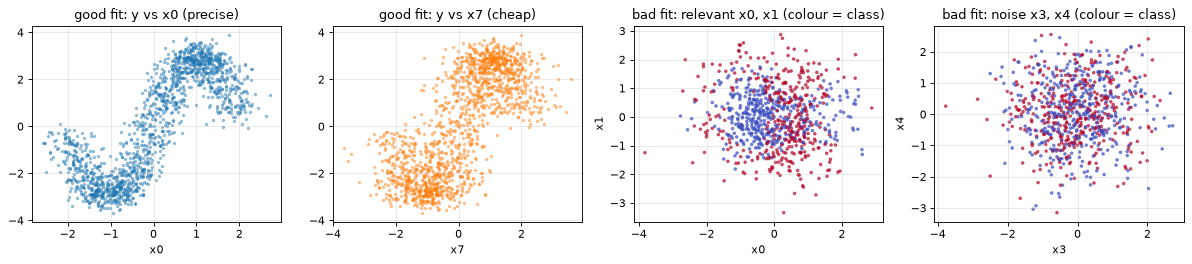

In [2]:
def make_good_fit(seed=0, n=1500):
    """31 noisy thermometers of one hidden signal z: x0 precise (s.d. 0.3), x1..x30 cheap (s.d. 0.6)."""
    rng = np.random.default_rng(seed)
    z = rng.uniform(-2, 2, n)
    noise_sd = np.r_[0.3, np.full(30, 0.6)]
    X = np.round(z[:, None] + noise_sd * rng.normal(size=(n, 31)), 4)
    y = np.round((3 * np.sin(1.5 * z) + 0.3 * rng.normal(size=n)) * 64) / 64
    return X, y


def make_bad_fit(seed=0, n=800, p=150):
    """150 standard-normal features; only x0, x1, x2 drive the binary label."""
    rng = np.random.default_rng(seed)
    X = np.round(rng.normal(size=(n, p)), 2)
    score = 1.5 * np.sin(2 * X[:, 0]) + X[:, 1] ** 2 - 1 + np.where(X[:, 2] > 0, 1.0, -1.0)
    y = (score + 0.5 * rng.normal(size=n) > 0).astype(int)
    return X, y


X_good, y_good = make_good_fit(seed=0)
X_bad, y_bad = make_bad_fit(seed=0)
np.savetxt(DATA / "good_fit.csv", np.column_stack([X_good, y_good]), delimiter=",",
           header=",".join([f"x{j}" for j in range(31)] + ["y"]), comments="", fmt=["%.4f"] * 31 + ["%.6f"])
np.savetxt(DATA / "bad_fit.csv", np.column_stack([X_bad, y_bad]), delimiter=",",
           header=",".join([f"x{j}" for j in range(150)] + ["y"]), comments="", fmt=["%.2f"] * 150 + ["%d"])
for name in ["good_fit.csv", "bad_fit.csv"]:
    print(f"{name}: {(DATA / name).stat().st_size / 1e3:.0f} KB")
print("good fit:", X_good.shape, " bad fit:", X_bad.shape, " class balance:", y_bad.mean().round(3))

# one train/test split per dataset, used everywhere below (test set = touched once per comparison)
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(X_good, y_good, test_size=1 / 3, random_state=0)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_bad, y_bad, test_size=0.3, random_state=0, stratify=y_bad)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
axes[0].scatter(X_good[:, 0], y_good, s=4, alpha=0.4)
axes[0].set_title("good fit: y vs x0 (precise)"); axes[0].set_xlabel("x0")
axes[1].scatter(X_good[:, 7], y_good, s=4, alpha=0.4, color="tab:orange")
axes[1].set_title("good fit: y vs x7 (cheap)"); axes[1].set_xlabel("x7")
for ax, (a, b) in zip(axes[2:], [(0, 1), (3, 4)]):
    ax.scatter(X_bad[:, a], X_bad[:, b], c=y_bad, s=5, cmap="coolwarm", alpha=0.6)
    ax.set_xlabel(f"x{a}"); ax.set_ylabel(f"x{b}")
axes[2].set_title("bad fit: relevant x0, x1 (colour = class)")
axes[3].set_title("bad fit: noise x3, x4 (colour = class)")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left two panels: `y` is a sine of the hidden signal. The precise thermometer `x0` shows the sine clearly; a cheap
>   one (`x7`) shows it more blurred — informative, but weaker.
> * Right two panels: in the relevant features `x0, x1` the two colours occupy different regions; in noise features
>   `x3, x4` they are perfectly mixed. 147 of the 150 bad-fit features look like the last panel.
> * Both CSVs are written to `data/` (the from-scratch notebook loads them) and stay well under 1 MB.

---
# Part A — How a random forest works

## Lab 1 · The hand-worked example, done by the computer

**Goal:** reproduce README section 5 number by number:
(a) the variance formula $\text{Var} = \rho\sigma^2 + (1-\rho)\sigma^2/B$ for bagging-like vs forest-like trees,
checked by simulation; (b) the 8-row tree, its Gini impurities and its MDI importances 0.6 / 0.4.

In [3]:
def ensemble_variance(rho, sigma2, B):
    """Variance of the average of B predictions, each with variance sigma2 and pairwise correlation rho."""
    return rho * sigma2 + (1 - rho) * sigma2 / B


for label, rho, sigma2 in [("bagging-like", 0.8, 4.0), ("forest-like ", 0.3, 5.0)]:
    print(f"{label}: one tree {sigma2}, B=100 -> {ensemble_variance(rho, sigma2, 100):.3f}, "
          f"B=infinity -> {rho * sigma2:.3f}")

# simulation: B correlated 'tree outputs' = shared part + private part
rng = np.random.default_rng(0)
for rho, sigma2 in [(0.8, 4.0), (0.3, 5.0)]:
    shared = rng.normal(size=(100_000, 1))
    private = rng.normal(size=(100_000, 100))
    trees = np.sqrt(sigma2) * (np.sqrt(rho) * shared + np.sqrt(1 - rho) * private)
    print(f"simulated rho={rho}, sigma2={sigma2}: variance of the average of 100 = {trees.mean(axis=1).var():.3f}")

bagging-like: one tree 4.0, B=100 -> 3.208, B=infinity -> 3.200
forest-like : one tree 5.0, B=100 -> 1.535, B=infinity -> 1.500


simulated rho=0.8, sigma2=4.0: variance of the average of 100 = 3.209
simulated rho=0.3, sigma2=5.0: variance of the average of 100 = 1.523


In [4]:
X_toy = np.array([[1, 2], [2, 4], [3, 6], [4, 8], [5, 3], [6, 1], [7, 5], [8, 7]], dtype=float)
y_toy = np.array([0, 0, 0, 0, 1, 0, 1, 1])          # 0 = class A, 1 = class B


def gini(labels):
    """Gini impurity 1 - sum_k p_k^2 of a set of labels."""
    p = np.bincount(labels, minlength=2) / len(labels)
    return 1 - np.sum(p ** 2)


root, left, right = y_toy, y_toy[X_toy[:, 0] <= 4.5], y_toy[X_toy[:, 0] > 4.5]
print("Gini root =", gini(root), "  left =", gini(left), "  right =", gini(right))
decrease_root = 1.0 * (gini(root) - 4 / 8 * gini(left) - 4 / 8 * gini(right))     # N_t/N = 8/8
decrease_right = 4 / 8 * (gini(right) - 1 / 4 * 0.0 - 3 / 4 * 0.0)                # N_t/N = 4/8, pure children
print("weighted impurity decrease: root (x1) =", decrease_root, "  right node (x2) =", decrease_right)
print("MDI by hand:", np.array([decrease_root, decrease_right]) / (decrease_root + decrease_right))

toy_tree = DecisionTreeClassifier(random_state=0).fit(X_toy, y_toy)
print("sklearn tree: features", toy_tree.tree_.feature, " thresholds", toy_tree.tree_.threshold)
print("sklearn feature_importances_:", toy_tree.feature_importances_)

Gini root = 0.46875   left = 0.0   right = 0.375
weighted impurity decrease: root (x1) = 0.28125   right node (x2) = 0.1875
MDI by hand: [0.6 0.4]
sklearn tree: features [ 0 -2  1 -2 -2]  thresholds [ 4.5 -2.   2.  -2.  -2. ]
sklearn feature_importances_: [0.6 0.4]


> **How to read this**
> * **Variance formula.** Bagging-like trees (ρ = 0.8, σ² = 4): 100 of them give **3.208** — hardly better than one
>   tree's 4, and no number of trees can go below the floor ρσ² = **3.2**. Forest-like trees (ρ = 0.3, σ² = 5) are each
>   *worse* (5 > 4), yet 100 of them give **1.535** (floor 1.5). Less correlated beats individually better.
> * The simulation (100,000 repetitions of averaging 100 correlated numbers) prints 3.209 and 1.523 — the formula
>   holds; the small gaps are simulation noise.
> * **The 8-row tree.** Root Gini 0.46875; the split `x1 <= 4.5` leaves a pure left child (Gini 0) and a right child
>   with Gini 0.375. Weighted decreases: **0.28125** at the root (x1) and **0.1875** at the right node (x2), so the MDI
>   is 0.28125 / 0.46875 = **0.6** for x1 and **0.4** for x2. scikit-learn grows the same tree (feature 0 at 4.5,
>   feature 1 at 2.0) and reports `[0.6, 0.4]`.

## Lab 2 · Inside a fitted tree: the `tree_` arrays, and a correct MDI

**Goal:** understand what scikit-learn stores in `tree_` (the old notes printed these arrays without explaining
them), rebuild MDI from those arrays, and show why the **old custom MDI** (`feature_idx - 1`, summing raw impurity)
disagreed with `feature_importances_`.

* `children_left[i]`, `children_right[i]` — the node numbers of node *i*'s children; `-1` means *i* is a leaf.
* `feature[i]`, `threshold[i]` — the question asked at node *i*: "is `x[feature] <= threshold`?" (`-2` at leaves).
* `impurity[i]` — Gini (classification) or MSE (regression) of the training rows that reached node *i*.
* `n_node_samples[i]` — how many distinct training rows reached it; `weighted_n_node_samples[i]` — the same, but
  each row counted with its sample weight (in a forest: **how many times the bootstrap drew it**).
* `value[i]` — the prediction stored at the node. For a classifier in scikit-learn ≥ 1.4 these are **class
  fractions** (they sum to 1); multiply by `weighted_n_node_samples` to get the (weighted) class counts that older
  versions — and the old notes — printed.

In [5]:
t = toy_tree.tree_
print("children_left          :", t.children_left)
print("children_right         :", t.children_right)
print("feature                :", t.feature)
print("impurity               :", t.impurity)
print("n_node_samples         :", t.n_node_samples)
print("weighted_n_node_samples:", t.weighted_n_node_samples)
print("value (class fractions):\n", t.value[:, 0, :])
print("value x weighted_n (= class counts):\n", t.value[:, 0, :] * t.weighted_n_node_samples[:, None])


def mdi_from_tree(t, n_features):
    """Correct MDI: sum over split nodes of (N_t/N)*[imp_t - (N_L/N_t) imp_L - (N_R/N_t) imp_R], then normalise."""
    importance = np.zeros(n_features)
    for node in np.flatnonzero(t.children_left != -1):              # split nodes only
        L, R = t.children_left[node], t.children_right[node]
        w, wL, wR = t.weighted_n_node_samples[[node, L, R]]
        importance[t.feature[node]] += (w * t.impurity[node] - wL * t.impurity[L] - wR * t.impurity[R])
    importance /= t.weighted_n_node_samples[0]                       # the N_t/N factor
    return importance / importance.sum()


def mdi_old_buggy(t, n_features):
    """The old notes' version: index feature-1 and add the node's raw impurity (not its decrease)."""
    importance = np.zeros(n_features)
    for node, feat in enumerate(t.feature):
        if feat != -2:
            importance[feat - 1] += t.impurity[node]
    return importance / importance.sum()


print("\ncorrect MDI:", mdi_from_tree(t, 2), "  old buggy MDI:", mdi_old_buggy(t, 2),
      "  sklearn:", toy_tree.feature_importances_)

children_left          : [ 1 -1  3 -1 -1]
children_right         : [ 2 -1  4 -1 -1]
feature                : [ 0 -2  1 -2 -2]
impurity               : [0.469 0.    0.375 0.    0.   ]
n_node_samples         : [8 4 4 1 3]
weighted_n_node_samples: [8. 4. 4. 1. 3.]
value (class fractions):
 [[0.625 0.375]
 [1.    0.   ]
 [0.25  0.75 ]
 [1.    0.   ]
 [0.    1.   ]]
value x weighted_n (= class counts):
 [[5. 3.]
 [4. 0.]
 [1. 3.]
 [1. 0.]
 [0. 3.]]

correct MDI: [0.6 0.4]   old buggy MDI: [0.444 0.556]   sklearn: [0.6 0.4]


In [6]:
rf_bad = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1).fit(Xb_tr, yb_tr)
one = rf_bad.estimators_[0].tree_
print(f"one forest tree: {one.node_count} nodes, root has {one.n_node_samples[0]} distinct rows but "
      f"weighted_n = {one.weighted_n_node_samples[0]:.0f} (= number of bootstrap draws)")

per_tree_mdi = np.array([mdi_from_tree(est.tree_, 150) for est in rf_bad.estimators_])
forest_mdi = per_tree_mdi.mean(axis=0) / per_tree_mdi.mean(axis=0).sum()
buggy = np.array([mdi_old_buggy(est.tree_, 150) for est in rf_bad.estimators_]).mean(axis=0)
print("max |correct - sklearn| :", np.abs(forest_mdi - rf_bad.feature_importances_).max())
print("max |buggy   - sklearn| :", np.abs(buggy - rf_bad.feature_importances_).max())
print("top-3 features  correct:", np.argsort(forest_mdi)[::-1][:3], "  buggy:", np.argsort(buggy)[::-1][:3])
print("importance of x0, x1, x2  correct:", forest_mdi[:3], "  buggy:", buggy[:3])

one forest tree: 133 nodes, root has 353 distinct rows but weighted_n = 560 (= number of bootstrap draws)


max |correct - sklearn| : 2.0816681711721685e-17
max |buggy   - sklearn| : 0.08015728274130225
top-3 features  correct: [2 1 0]   buggy: [  1   0 149]
importance of x0, x1, x2  correct: [0.045 0.052 0.087]   buggy: [0.026 0.028 0.007]


> **How to read this**
> * Read the arrays as a tree: node 0 (the root, 8 rows, Gini 0.469) has children 1 and 2. Node 1 is a leaf
>   (`-1`, `-1`). Node 2 asks about feature 1 (x2) and has leaves 3 and 4. `value` holds fractions — the root's
>   `[0.625, 0.375]` times its 8 rows is 5 A and 3 B, the counts the old notes printed.
> * MDI rebuilt from the arrays = `[0.6, 0.4]` = scikit-learn. The **old version gives `[0.444, 0.556]` and ranks x2
>   first**: `feature - 1` sent the root's contribution to the wrong feature (index −1 even wraps around to the last
>   one), and adding *raw impurity* rewards a node for being messy instead of for cleaning up.
> * In a forest tree the root holds 353 distinct rows but `weighted_n_node_samples` = 560: the weights are the
>   bootstrap counts. Rebuilt MDI of the 100-tree bad-fit forest matches `feature_importances_` to 2e-17 (rounding);
>   the old version is off by up to 0.08 and its "top 3" `[1, 0, 149]` contains a pure-noise feature, while the
>   correct top 3 `[2, 1, 0]` are exactly the three real features.
> * Notice how little importance x0, x1, x2 get (0.045, 0.052, 0.087): the 147 noise features share the rest.
>   Lab 11 explains why.

## Lab 3 · Per-split vs per-tree feature sampling (the one key difference from bagging)

**Goal:** a random forest draws `max_features` candidate features **at every split**; the "random subspace" variant
of bagging draws them **once per tree**. Compare both (5 of 31 features each) with plain bagging (all 31) on the
good-fit data, and look at *which* features the trees use. Also check scikit-learn's defaults: for the regressor the
default `max_features=1.0` means **no feature sampling at all** — the default `RandomForestRegressor` *is* bagged trees.

In [7]:
print("defaults in this scikit-learn: classifier max_features =", RandomForestClassifier().max_features,
      "| regressor max_features =", RandomForestRegressor().max_features)

models = {
    "bagging (all 31 at every split)": RandomForestRegressor(200, max_features=1.0, random_state=0, n_jobs=-1),
    "random subspace (5 per TREE)": BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, max_features=5,
                                                      random_state=0, n_jobs=-1),
    "random forest (5 per SPLIT)": RandomForestRegressor(200, max_features=5, random_state=0, n_jobs=-1),  # <- try 2, 10
}
default_reg = RandomForestRegressor(200, random_state=0, n_jobs=-1).fit(Xg_tr, yg_tr)
for name, model in models.items():
    model.fit(Xg_tr, yg_tr)
    roots = np.array([est.tree_.feature[0] for est in model.estimators_])
    if name.startswith("random subspace"):   # map the tree's local feature index back to the original column
        roots = np.array([feats[r] for r, feats in zip(roots, model.estimators_features_)])
    used = [len(np.unique(est.tree_.feature[est.tree_.feature >= 0])) for est in model.estimators_]
    print(f"{name:34s} test MSE {mean_squared_error(yg_te, model.predict(Xg_te)):.3f} | "
          f"root split on x0 in {np.mean(roots == 0):4.0%} of trees | distinct features per tree {np.mean(used):4.1f}")
same = np.allclose(default_reg.predict(Xg_te), models["bagging (all 31 at every split)"].predict(Xg_te))
print("default RandomForestRegressor() identical to max_features=1.0 (bagging)?", same)

defaults in this scikit-learn: classifier max_features = sqrt | regressor max_features = 1.0


bagging (all 31 at every split)    test MSE 0.343 | root split on x0 in 100% of trees | distinct features per tree 31.0


random subspace (5 per TREE)       test MSE 0.352 | root split on x0 in  16% of trees | distinct features per tree  5.0
random forest (5 per SPLIT)        test MSE 0.299 | root split on x0 in  14% of trees | distinct features per tree 31.0
default RandomForestRegressor() identical to max_features=1.0 (bagging)? True


> **How to read this**
> * This scikit-learn's defaults are `'sqrt'` for the classifier and `1.0` for the regressor — and the last line
>   confirms that the default `RandomForestRegressor()` gives **identical** predictions to `max_features=1.0`: it is
>   bagged trees. (So the old notes' "random forest regressor", MSE 7365 vs 7363 with `max_features=0.8`, compared
>   bagging with almost-bagging.)
> * **Bagging:** 100 % of the trees ask their first question about x0 — every tree starts the same way, so their
>   errors are alike. **Random subspace (5 per tree):** only 16 % of trees can use x0 at all, and each tree is stuck
>   with 5 features for its whole life. **Random forest (5 per split):** x0 is the root in 14 % of trees, but every tree
>   still uses all 31 features somewhere, and x0 is available again at every later split.
> * Test MSE: random forest **0.299** < bagging 0.343 < random subspace 0.352. Per-tree sampling decorrelates the
>   trees but permanently weakens each one; per-split sampling decorrelates them while every tree can still reach
>   every feature.

## Lab 4 · Decorrelation: how `max_features` trades ρ against σ²

**Goal:** measure the two ingredients of README §4. For each `max_features` value we fit a forest and compute, on
the test set, every tree's error vector $e_b = T_b(x) - y$. Then

* $\sigma^2$ = average single-tree MSE (how bad one tree is), and
* $\rho$ = average over pairs of $\overline{e_b e_{b'}}/\sigma^2$ (how *similar* two trees' mistakes are; 1 = identical).

With those definitions the formula $\text{MSE}_\text{forest} = \rho\sigma^2 + (1-\rho)\sigma^2/B$ holds **exactly**
(it is just expanding the square of an average), so we can watch the trade-off number by number.

 m    rho    sigma2  rho*s2+(1-rho)*s2/B   forest test MSE
 1  0.268   1.185        0.3218           0.3218
 2  0.279   1.094        0.3088           0.3088
 3  0.284   1.041        0.2997           0.2997
 5  0.297   0.992        0.2986           0.2986
 8  0.311   0.941        0.2956           0.2956
12  0.332   0.911        0.3053           0.3053
20  0.373   0.872        0.3278           0.3278
31  0.404   0.841        0.3426           0.3426


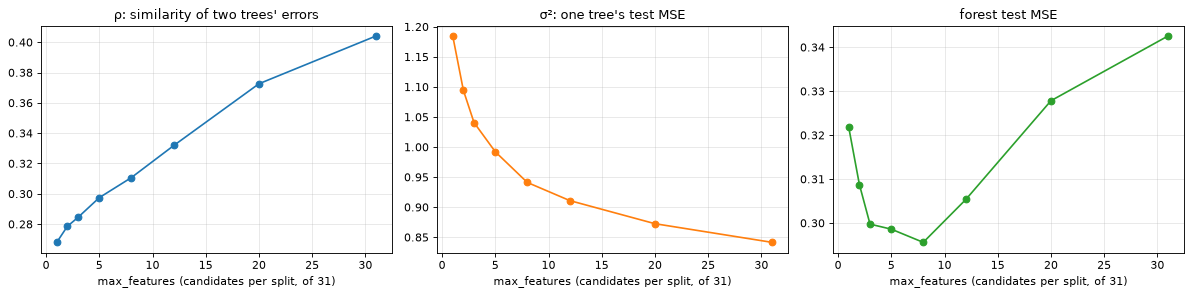

In [8]:
B = 200
m_values = [1, 2, 3, 5, 8, 12, 20, 31]                                # <- try changing this
rows, corr_heatmaps = [], {}
for m in m_values:
    forest = RandomForestRegressor(B, max_features=m, random_state=0, n_jobs=-1).fit(Xg_tr, yg_tr)
    E = tree_predictions(forest, Xg_te) - yg_te                       # (B, n_test) error matrix
    G = E @ E.T / E.shape[1]                                          # mean e_b * e_b' for every pair
    sigma2 = np.mean(np.diag(G))
    rho = (G.sum() - np.trace(G)) / (B * (B - 1)) / sigma2
    mse = mean_squared_error(yg_te, forest.predict(Xg_te))
    rows.append((m, rho, sigma2, ensemble_variance(rho, sigma2, B), mse))
    if m in (5, 31):
        corr_heatmaps[m] = np.corrcoef(E[:50])                        # first 50 trees, for the heatmaps

print(" m    rho    sigma2  rho*s2+(1-rho)*s2/B   forest test MSE")
for m, rho, s2, formula, mse in rows:
    print(f"{m:2d}  {rho:.3f}   {s2:.3f}        {formula:.4f}           {mse:.4f}")

r = np.array(rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(r[:, 0], r[:, 1], "o-"); axes[0].set_title("ρ: similarity of two trees' errors")
axes[1].plot(r[:, 0], r[:, 2], "o-", color="tab:orange"); axes[1].set_title("σ²: one tree's test MSE")
axes[2].plot(r[:, 0], r[:, 4], "o-", color="tab:green"); axes[2].set_title("forest test MSE")
for ax in axes:
    ax.set_xlabel("max_features (candidates per split, of 31)")
plt.tight_layout(); plt.show()

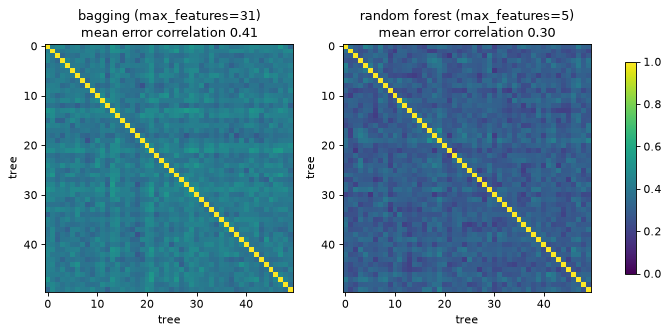

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, m, title in [(axes[0], 31, "bagging (max_features=31)"), (axes[1], 5, "random forest (max_features=5)")]:
    im = ax.imshow(corr_heatmaps[m], vmin=0, vmax=1, cmap="viridis")
    off = corr_heatmaps[m][~np.eye(50, dtype=bool)]
    ax.set_title(f"{title}\nmean error correlation {off.mean():.2f}")
    ax.set_xlabel("tree"); ax.set_ylabel("tree"); ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

> **How to read this**
> * The formula column equals the measured forest MSE in every row (to 4 decimals): with these definitions
>   $\rho\sigma^2 + (1-\rho)\sigma^2/B$ is exact algebra, not an approximation.
> * **ρ falls** steadily from 0.404 (m = 31, bagging) to 0.268 (m = 1) — fewer candidates, less alike trees.
>   **σ² rises** from 0.841 to 1.185 — fewer candidates, each tree is worse.
> * The forest error is therefore **U-shaped**: 0.343 at m = 31, best **0.296 at m = 8**, back up to 0.322 at m = 1.
>   Breiman's p/3 ≈ 10 and √31 ≈ 5 both sit in the flat bottom.
> * With B = 200 the second term $(1-\rho)\sigma^2/B$ is tiny (≈ 0.0025 for bagging), so forest MSE ≈ ρσ²:
>   **correlation, not the number of trees, is what limits a forest.**
> * Heatmaps (ordinary correlation of the first 50 trees' errors): bagging is lighter (mean 0.41), the random forest
>   darker (mean 0.30). This is the old notes' "correlation of residuals" heatmap, now used to compare the two.

---
# Part B — Why a random forest is useful

## Lab 5 · One tree vs bagging vs random forest on the good-fit data

**Goal:** the headline comparison, plus the old notes' "base trees vs the forest" check. Every model is trained on
the same training set and scored once on the same test set. We also look at each individual tree of the forest: are
they "weak learners"?

one deep tree                                        test MSE 0.703   R² 0.858


bagging (max_features=1.0, the regressor default)    test MSE 0.342   R² 0.931
random forest (max_features=1/3, Breiman's p/3)      test MSE 0.298   R² 0.940


random forest (max_features='sqrt')                  test MSE 0.299   R² 0.940
extra trees (max_features='sqrt')                    test MSE 0.270   R² 0.945
linear regression                                    test MSE 1.639   R² 0.668



the forest's own trees: R² 1.000 on the rows each tree was trained on, R² 0.799 on the test set (0 = predicting the mean, 1 = perfect)
their test MSE ranges from 0.755 to 1.265, mean 0.992
forest test MSE 0.299 is lower than 100% of its own trees


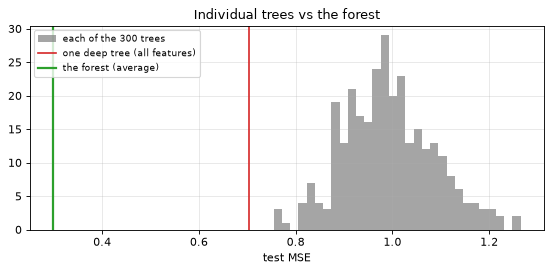

In [10]:
contenders = {
    "one deep tree": DecisionTreeRegressor(random_state=0),
    "bagging (max_features=1.0, the regressor default)": RandomForestRegressor(300, max_features=1.0, random_state=0, n_jobs=-1),
    "random forest (max_features=1/3, Breiman's p/3)": RandomForestRegressor(300, max_features=1 / 3, random_state=0, n_jobs=-1),
    "random forest (max_features='sqrt')": RandomForestRegressor(300, max_features="sqrt", random_state=0, n_jobs=-1),
    "extra trees (max_features='sqrt')": ExtraTreesRegressor(300, max_features="sqrt", random_state=0, n_jobs=-1),
    "linear regression": LinearRegression(),
}
for name, model in contenders.items():
    model.fit(Xg_tr, yg_tr)
    print(f"{name:52s} test MSE {mean_squared_error(yg_te, model.predict(Xg_te)):.3f}   "
          f"R² {r2_score(yg_te, model.predict(Xg_te)):.3f}")

rf_good = contenders["random forest (max_features='sqrt')"]
tree_mse = np.array([mean_squared_error(yg_te, p) for p in tree_predictions(rf_good, Xg_te)])
in_bag_r2 = np.mean([r2_score(yg_tr[np.unique(idx)], est.predict(Xg_tr[np.unique(idx)]))
                     for est, idx in zip(rf_good.estimators_, rf_good.estimators_samples_)])
tree_test_r2 = np.mean([r2_score(yg_te, p) for p in tree_predictions(rf_good, Xg_te)])
print(f"\nthe forest's own trees: R² {in_bag_r2:.3f} on the rows each tree was trained on, "
      f"R² {tree_test_r2:.3f} on the test set (0 = predicting the mean, 1 = perfect)")
print(f"their test MSE ranges from {tree_mse.min():.3f} to {tree_mse.max():.3f}, mean {tree_mse.mean():.3f}")
print(f"forest test MSE {mean_squared_error(yg_te, rf_good.predict(Xg_te)):.3f} is lower than "
      f"{np.mean(tree_mse > mean_squared_error(yg_te, rf_good.predict(Xg_te))):.0%} of its own trees")

plt.figure(figsize=(7, 3.5))
plt.hist(tree_mse, bins=30, color="tab:gray", alpha=0.7, label="each of the 300 trees")
plt.axvline(mean_squared_error(yg_te, contenders["one deep tree"].predict(Xg_te)), color="tab:red", label="one deep tree (all features)")
plt.axvline(mean_squared_error(yg_te, rf_good.predict(Xg_te)), color="tab:green", lw=2, label="the forest (average)")
plt.xlabel("test MSE"); plt.legend(fontsize=8); plt.title("Individual trees vs the forest")
plt.tight_layout(); plt.show()

> **How to read this**
> * Test MSE: one deep tree 0.703 → bagging 0.342 → random forest **0.298–0.299** (both standard recipes) → extra
>   trees 0.270. A straight line (1.639) cannot follow the sine. The forest removes 13 % of bagging's error; since
>   ≈ 0.18 is pure noise (Lab 6), it removes about a quarter of the *reducible* error.
> * The forest's trees are **not weak learners**: each fits its own training rows perfectly (R² 1.000) and still
>   explains about 80 % of the test variance (R² 0.799). "Weak learner" is a boosting term for a model barely better
>   than guessing; forest trees are strong but *unstable* (low bias, high variance).
> * Histogram: every single tree (test MSE 0.755–1.265) is worse than one ordinary deep tree (0.703) — each sees only
>   a bootstrap sample and restricted candidates. Yet the forest (0.299) beats **100 %** of its own trees. The gain
>   comes entirely from averaging.
> * Extra trees (README §6.2) also randomise the thresholds: even less correlated trees, here slightly better.

## Lab 6 · Bias stays, variance falls — measured across 30 independent training sets

**Goal:** the old notes compared the *spread between the trees of one forest*; that is not the variance of the
forest's prediction. The variance that matters is: **if I had collected a different training set, how much would
the forest's prediction at the same point change?** We can measure that because we can draw as many training sets
as we like from `make_good_fit`. And because we know how the data were generated, we can compute the *best possible*
prediction $f(x) = E[y \mid x]$ (by averaging over the values of `z` that the 31 thermometer readings make plausible),
so we can split each model's error into bias² + variance + noise.

In [11]:
NOISE_SD = np.r_[0.3, np.full(30, 0.6)]


def best_possible_prediction(X):
    """E[y | x] for the good-fit generator: average 3 sin(1.5 z) over z, weighted by how well z explains x."""
    z_grid = np.linspace(-2, 2, 2001)
    log_lik = -0.5 * (((X[:, None, :] - z_grid[None, :, None]) / NOISE_SD) ** 2).sum(axis=2)
    weights = np.exp(log_lik - log_lik.max(axis=1, keepdims=True))
    return (weights * 3 * np.sin(1.5 * z_grid)).sum(axis=1) / weights.sum(axis=1)


X_probe, y_probe = make_good_fit(seed=999, n=300)                   # fixed points at which we measure
f_probe = best_possible_prediction(X_probe)
recipes = {
    "one deep tree": lambda s: DecisionTreeRegressor(random_state=s),
    "one randomised tree (5 per split)": lambda s: DecisionTreeRegressor(max_features=5, random_state=s),
    "bagging (200 trees)": lambda s: RandomForestRegressor(200, max_features=1.0, random_state=s, n_jobs=-1),
    "random forest (200 trees, 5 per split)": lambda s: RandomForestRegressor(200, max_features=5, random_state=s, n_jobs=-1),
}
preds = {name: [] for name in recipes}
for s in range(30):                                                  # <- try more training sets
    X_s, y_s = make_good_fit(seed=100 + s, n=1000)
    for name, make in recipes.items():
        preds[name].append(make(s).fit(X_s, y_s).predict(X_probe))

noise = np.mean((y_probe - f_probe) ** 2)
print(f"irreducible noise E[(y - f(x))^2] at the probe points ≈ {noise:.3f}\n")
print(f"{'model':40s} bias²    variance   bias²+var+noise   measured MSE")
for name, P in preds.items():
    P = np.array(P)                                                  # (30 training sets, 300 points)
    S = len(P)
    var = np.mean(P.var(axis=0, ddof=1))
    # the average of only S predictions still wobbles by var/S; subtract that to get an unbiased bias²
    bias2 = np.mean((P.mean(axis=0) - f_probe) ** 2) - var / S
    mse = np.mean((P - y_probe) ** 2)
    print(f"{name:40s} {bias2:.4f}   {var:.4f}     {bias2 + var + noise:.4f}           {mse:.4f}")

irreducible noise E[(y - f(x))^2] at the probe points ≈ 0.180

model                                    bias²    variance   bias²+var+noise   measured MSE
one deep tree                            0.1057   0.4943     0.7795           0.7769
one randomised tree (5 per split)        0.0795   0.6760     0.9351           0.9245
bagging (200 trees)                      0.1131   0.0368     0.3295           0.3296
random forest (200 trees, 5 per split)   0.0832   0.0170     0.2797           0.2736


> **How to read this**
> * In every row bias² + variance + noise ≈ the measured MSE (e.g. 0.7795 vs 0.7769): the decomposition works.
> * **Averaging leaves the bias alone.** One deep tree 0.106 vs bagging 0.113 (a touch higher, because bagged trees
>   see bootstrap samples with only ~63 % distinct rows); one randomised tree 0.080 vs random forest 0.083.
> * **Averaging removes variance.** 0.494 → 0.037 for bagging (13× smaller), 0.676 → 0.017 for the forest (40×). The
>   randomised tree has *more* variance than the full tree, yet averages far better — lower ρ.
> * Here the forest's bias is also lower than bagging's (0.083 vs 0.113). That is a property of this dataset: with all
>   31 candidates the trees lean almost only on x0 (83 % of the MDI, Lab 15) and ignore what the 30 cheap thermometers
>   add together. Usually restricting the candidates *raises* the bias a little, and on the bad-fit data (Lab 11) it
>   raises it a lot. The general rule: **a forest's bias is the bias of one of its randomised trees; the forest's job
>   is to cut variance.** (The old notes called RF "lower-bias" — averaging never does that.)
> * The old notes' "variance" was the spread *between the trees of one forest* — that is σ² of the trees, not how
>   much the forest's prediction would change with a new training set (and there it compared bagging with
>   `max_features=0.8`, i.e. almost-bagging).

## Lab 7 · More trees never over-fit; the size of each tree is the real knob

**Goal:** (left) grow one forest of 500 trees and watch the test error **and the out-of-bag (OOB) error** as trees
are added; (right) change how big each tree may grow (`min_samples_leaf`, `max_depth` — the "pruning" knobs the
old notes mentioned).

test MSE after   1, 10, 50, 100, 500 trees: [0.824 0.365 0.309 0.306 0.296]
OOB  MSE after   1, 10, 50, 100, 500 trees: [0.844 0.602 0.343 0.318 0.303]


min_samples_leaf: [1, 2, 5, 10, 20, 50, 100]
  train MSE     : [0.042 0.061 0.136 0.226 0.354 0.567 0.784]
  test MSE      : [0.299 0.298 0.327 0.387 0.49  0.679 0.877]
  nodes per tree: [1225.  550.  202.   98.   49.   20.   10.]
max_depth -> test MSE: [(2, 0.799), (4, 0.548), (6, 0.407), (8, 0.343), (12, 0.304), (None, 0.299)]


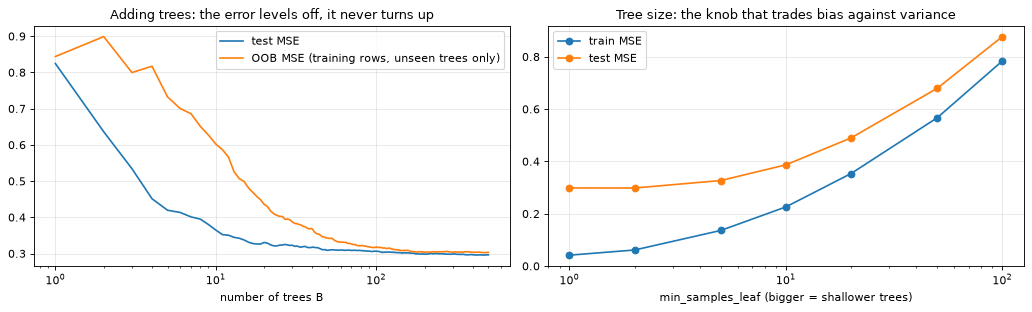

In [12]:
big = RandomForestRegressor(500, max_features="sqrt", random_state=0, n_jobs=-1).fit(Xg_tr, yg_tr)
P_test = tree_predictions(big, Xg_te)                                # (500, n_test)
P_train = tree_predictions(big, Xg_tr)                               # (500, n_train)
in_bag = np.zeros_like(P_train, dtype=bool)
for b, idx in enumerate(big.estimators_samples_):
    in_bag[b, idx] = True
oob = ~in_bag                                                        # tree b did NOT see training row i

counts = np.arange(1, 501)
test_curve = [mean_squared_error(yg_te, row) for row in np.cumsum(P_test, axis=0) / counts[:, None]]
oob_sum, oob_n = np.cumsum(P_train * oob, axis=0), np.cumsum(oob, axis=0)
oob_curve = [np.mean((s[n > 0] / n[n > 0] - yg_tr[n > 0]) ** 2) for s, n in zip(oob_sum, oob_n)]
print("test MSE after   1, 10, 50, 100, 500 trees:", np.round([test_curve[k - 1] for k in (1, 10, 50, 100, 500)], 3))
print("OOB  MSE after   1, 10, 50, 100, 500 trees:", np.round([oob_curve[k - 1] for k in (1, 10, 50, 100, 500)], 3))

leaf_sizes = [1, 2, 5, 10, 20, 50, 100]                              # <- try changing this
leaf_rows = []
for leaf in leaf_sizes:
    f = RandomForestRegressor(200, max_features="sqrt", min_samples_leaf=leaf, random_state=0, n_jobs=-1).fit(Xg_tr, yg_tr)
    leaf_rows.append((mean_squared_error(yg_tr, f.predict(Xg_tr)), mean_squared_error(yg_te, f.predict(Xg_te)),
                      np.mean([e.tree_.node_count for e in f.estimators_])))
depth_rows = []
for depth in [2, 4, 6, 8, 12, None]:
    f = RandomForestRegressor(200, max_features="sqrt", max_depth=depth, random_state=0, n_jobs=-1).fit(Xg_tr, yg_tr)
    depth_rows.append((depth, mean_squared_error(yg_te, f.predict(Xg_te))))
print("min_samples_leaf:", leaf_sizes)
print("  train MSE     :", np.round([r[0] for r in leaf_rows], 3))
print("  test MSE      :", np.round([r[1] for r in leaf_rows], 3))
print("  nodes per tree:", np.round([r[2] for r in leaf_rows], 0))
print("max_depth -> test MSE:", [(d, round(m, 3)) for d, m in depth_rows])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(counts, test_curve, label="test MSE")
axes[0].plot(counts, oob_curve, label="OOB MSE (training rows, unseen trees only)")
axes[0].set_xscale("log"); axes[0].set_xlabel("number of trees B"); axes[0].legend()
axes[0].set_title("Adding trees: the error levels off, it never turns up")
axes[1].plot(leaf_sizes, [r[0] for r in leaf_rows], "o-", label="train MSE")
axes[1].plot(leaf_sizes, [r[1] for r in leaf_rows], "o-", label="test MSE")
axes[1].set_xscale("log"); axes[1].set_xlabel("min_samples_leaf (bigger = shallower trees)"); axes[1].legend()
axes[1].set_title("Tree size: the knob that trades bias against variance")
plt.tight_layout(); plt.show()

> **How to read this**
> * Test MSE after 1, 10, 50, 100, 500 trees: 0.824, 0.365, 0.309, 0.306, 0.296 — it drops fast, then flattens, and
>   **never turns up**. More trees only shrink $(1-\rho)\sigma^2/B$ towards its floor; they cost time and memory,
>   not accuracy.
> * The OOB curve tracks the test curve (0.303 vs 0.296 at 500 trees). It is higher for small forests because each
>   row is out-of-bag for only ~37 % of the trees, so its OOB prediction averages fewer trees.
> * Right panel: `min_samples_leaf` from 1 to 100 raises train MSE 0.042 → 0.784 and test MSE 0.299 → 0.877, while
>   trees shrink from 1225 to 10 nodes. `max_depth` agrees (depth 2: 0.799, unlimited: 0.299). Here fully grown trees
>   are best: shallower trees have less variance but more **bias**, and averaging cannot remove bias.
> * The old notes' advice — `max_depth` / `min_samples_*` make trees shallower — is right; with a forest, start
>   fully grown and prune only if CV says so (very noisy targets) or to save memory and time (Lab 16).

## Lab 8 · The out-of-bag estimate ≈ cross-validation, for free

**Goal:** each tree leaves out ≈ 36.8 % of the training rows; predicting every row with only the trees that did not
see it gives an honest error estimate without a separate validation set. Compare it with 5-fold cross-validation
and with the (once-touched) test set — and compare the cost.

In [13]:
t0 = time.perf_counter()
rf_oob = RandomForestRegressor(300, max_features="sqrt", oob_score=True, random_state=0, n_jobs=-1).fit(Xg_tr, yg_tr)
t_oob = time.perf_counter() - t0
t0 = time.perf_counter()
cv_r2 = cross_val_score(RandomForestRegressor(300, max_features="sqrt", random_state=0, n_jobs=-1), Xg_tr, yg_tr,
                        cv=KFold(5, shuffle=True, random_state=0), scoring="r2")
t_cv = time.perf_counter() - t0
counts_per_row = np.sum([np.bincount(i, minlength=len(Xg_tr)) == 0 for i in rf_oob.estimators_samples_], axis=0)
print(f"each training row was out-of-bag for {counts_per_row.mean():.0f} of 300 trees on average "
      f"({counts_per_row.mean() / 300:.1%}; theory (1-1/n)^n ≈ {(1 - 1 / len(Xg_tr)) ** len(Xg_tr):.1%})")
print(f"OOB R²       = {rf_oob.oob_score_:.3f}   (one fit, {t_oob:.1f} s)")
print(f"5-fold CV R² = {cv_r2.mean():.3f} ± {cv_r2.std():.3f}   (five fits, {t_cv:.1f} s)")
print(f"test R²      = {rf_oob.score(Xg_te, yg_te):.3f}   (the held-out set, used once)")

each training row was out-of-bag for 110 of 300 trees on average (36.7%; theory (1-1/n)^n ≈ 36.8%)
OOB R²       = 0.935   (one fit, 0.2 s)
5-fold CV R² = 0.933 ± 0.006   (five fits, 0.7 s)
test R²      = 0.940   (the held-out set, used once)


> **How to read this**
> * Each training row was out-of-bag for 110 of 300 trees (36.7 %, theory 36.8 %).
> * OOB R² 0.935, 5-fold CV R² 0.933 ± 0.006, test R² 0.940: three estimates within 0.01 of each other.
> * OOB costs one fit (0.2 s) instead of five (0.7 s) — no data is held back and nothing is refitted.
> * Caveat: like CV with shuffled folds, OOB assumes the rows are independent. For time series or grouped rows
>   (several rows per patient), use a time-based or grouped split instead.

## Lab 9 · Tuning without touching the test set (cross-validation and OOB)

**Goal:** replace the old Optuna search (which picked the hyper-parameters with the highest **test** score — so the
reported test score was optimistic) with an honest procedure: choose `max_features` and `min_samples_leaf` by 5-fold
CV on the training set (and, as a cheaper alternative, by OOB score), then score the chosen model **once** on the
test set.

In [14]:
grid = {"max_features": [1, 2, 3, 5, 10, 31], "min_samples_leaf": [1, 3, 10]}   # <- try changing this
t0 = time.perf_counter()
search = GridSearchCV(RandomForestRegressor(150, random_state=0, n_jobs=-1), grid,
                      cv=KFold(5, shuffle=True, random_state=0), scoring="neg_mean_squared_error").fit(Xg_tr, yg_tr)
print(f"CV grid search: {len(search.cv_results_['params'])} settings x 5 folds in {time.perf_counter() - t0:.0f} s")
print("  best by CV :", search.best_params_, f" CV MSE {-search.best_score_:.3f}")

t0 = time.perf_counter()
oob_scores = {}
for mf in grid["max_features"]:
    for leaf in grid["min_samples_leaf"]:
        f = RandomForestRegressor(150, max_features=mf, min_samples_leaf=leaf, oob_score=True, random_state=0,
                                  n_jobs=-1).fit(Xg_tr, yg_tr)
        oob_scores[(mf, leaf)] = mean_squared_error(yg_tr, f.oob_prediction_)
best_oob = min(oob_scores, key=oob_scores.get)
print(f"OOB search: {len(oob_scores)} settings x 1 fit in {time.perf_counter() - t0:.0f} s")
print(f"  best by OOB: max_features={best_oob[0]}, min_samples_leaf={best_oob[1]}  OOB MSE {oob_scores[best_oob]:.3f}")

final = RandomForestRegressor(500, random_state=0, n_jobs=-1, **search.best_params_).fit(Xg_tr, yg_tr)
print(f"\nchosen model refit on the whole training set, scored ONCE on the test set: MSE "
      f"{mean_squared_error(yg_te, final.predict(Xg_te)):.3f}")
cv_table = -search.cv_results_["mean_test_score"].reshape(len(grid["max_features"]), len(grid["min_samples_leaf"]))
print("CV MSE table (rows = max_features, columns = min_samples_leaf):\n", cv_table)

CV grid search: 18 settings x 5 folds in 7 s
  best by CV : {'max_features': 5, 'min_samples_leaf': 1}  CV MSE 0.312


OOB search: 18 settings x 1 fit in 2 s
  best by OOB: max_features=5, min_samples_leaf=1  OOB MSE 0.308



chosen model refit on the whole training set, scored ONCE on the test set: MSE 0.296
CV MSE table (rows = max_features, columns = min_samples_leaf):
 [[0.339 0.362 0.476]
 [0.317 0.336 0.435]
 [0.313 0.331 0.421]
 [0.312 0.32  0.406]
 [0.32  0.333 0.41 ]
 [0.373 0.381 0.461]]


> **How to read this**
> * 5-fold CV picks `max_features=5, min_samples_leaf=1` (CV MSE 0.312). The OOB search picks the **same** setting
>   (OOB MSE 0.308) in about a quarter of the time (2 s vs 8 s).
> * The CV table shows the U-shape of Lab 4 in every column (0.339 at m = 1, 0.312 at m = 5, 0.373 at m = 31) and
>   that larger leaves hurt in every row.
> * The test set is used **once**, for the final model: MSE 0.296. That number is an honest estimate. The old Optuna
>   run reported the best of 50 *test* scores, which is optimistic by construction — and an 18-setting grid (or a
>   `RandomizedSearchCV`) is plenty for a forest; no extra library is needed.

## Lab 10 · Mean or median of the trees? (testing an idea from the old notes)

**Goal:** a forest averages its trees. The old notes asked: why not take the **median** instead? We compute both
from the same trees, on (a) the clean good-fit data and (b) the same data where 5 % of the training targets are
corrupted by ±20 (gross recording errors). We also include plain bagging and `make_friedman1` (a standard smooth
benchmark) so the answer is not tied to one dataset.

In [15]:
def mean_vs_median(forest, X_test, y_test):
    P = tree_predictions(forest, X_test)
    return mean_squared_error(y_test, P.mean(axis=0)), mean_squared_error(y_test, np.median(P, axis=0))


rng = np.random.default_rng(1)
y_dirty = yg_tr.copy()
bad_rows = rng.choice(len(y_dirty), size=int(0.05 * len(y_dirty)), replace=False)   # <- try 0.02 or 0.10
y_dirty[bad_rows] += 20 * rng.choice([-1, 1], size=len(bad_rows))
X_fr, y_fr = make_friedman1(n_samples=1500, noise=1.0, random_state=0)

print(f"{'setting':58s} mean-MSE  median-MSE")
for label, X_fit, y_fit, X_eval, y_eval in [
        ("good fit, clean targets", Xg_tr, yg_tr, Xg_te, yg_te),
        ("good fit, 5% of training targets corrupted by ±20", Xg_tr, y_dirty, Xg_te, yg_te),
        ("make_friedman1 (smooth benchmark)", X_fr[:1000], y_fr[:1000], X_fr[1000:], y_fr[1000:])]:
    for mf in [1.0, "sqrt"]:
        forest = RandomForestRegressor(300, max_features=mf, random_state=0, n_jobs=-1).fit(X_fit, y_fit)
        mean_mse, median_mse = mean_vs_median(forest, X_eval, y_eval)
        kind = "bagging" if mf == 1.0 else "RF sqrt"
        print(f"{label + ' [' + kind + ']':58s} {mean_mse:7.3f}   {median_mse:7.3f}")

setting                                                    mean-MSE  median-MSE


good fit, clean targets [bagging]                            0.342     0.339
good fit, clean targets [RF sqrt]                            0.299     0.270


good fit, 5% of training targets corrupted by ±20 [bagging]   2.779     1.040
good fit, 5% of training targets corrupted by ±20 [RF sqrt]   1.027     0.263


make_friedman1 (smooth benchmark) [bagging]                  3.802     4.077
make_friedman1 (smooth benchmark) [RF sqrt]                  3.770     3.720


> **How to read this**
> * Clean targets, bagging: mean 0.342 vs median 0.339 — a tie. Clean targets, RF (5 per split): median **better**,
>   0.299 → 0.270: with only 5 candidates some trees lean on poor thermometers for a given point and make wild guesses;
>   the median ignores them.
> * Corrupted targets: mean 2.779 (bagging) / 1.027 (RF) vs median 1.040 / **0.263** — the RF median is as good as on
>   clean data (0.270). A deep tree gives a corrupted row its own leaf, so every tree containing that row predicts
>   ±20 near it; the mean averages that in, the median outvotes it.
> * `make_friedman1`: for bagging the median is **worse** (3.802 → 4.077); for RF slightly better (3.770 → 3.720).
> * Verdict on the old idea: the median is a *robust* aggregator, worth trying when targets may contain gross errors
>   or trees are heavily randomised. It is not universally better, scikit-learn's `predict`, `oob_score_` and the
>   theory of §4 are about the mean, and the better first fix for corrupted targets is to find and fix them.

---
# Part C — Where a random forest fails (and why)

## Lab 11 · A few relevant features hidden among many (the bad-fit dataset)

**Goal:** with 3 relevant features out of 150, how often does a split even *see* a relevant feature? What does that
do to accuracy, and which fixes work: a larger `max_features` (chosen by OOB), feature selection (inside a pipeline,
so it is re-done on each training fold), or boosting?

In [16]:
def chance_split_sees_signal(m, p=150, relevant=3):
    """1 - P(all m candidates are noise), drawing m of p features without replacement."""
    return 1 - np.prod([(p - relevant - i) / (p - i) for i in range(m)])


for m in [1, 12, 50, 150]:
    print(f"max_features={m:3d}: chance a split sees >= 1 relevant feature = {chance_split_sees_signal(m):.1%}")

m_grid = [1, 3, 12, 25, 50, 100, 150]                                # 12 = sqrt(150), the classifier default
acc_rows = []
for m in m_grid:
    f = RandomForestClassifier(300, max_features=m, oob_score=True, random_state=0, n_jobs=-1).fit(Xb_tr, yb_tr)
    tree_acc = np.mean([accuracy_score(yb_te, est.predict(Xb_te)) for est in f.estimators_[:50]])
    acc_rows.append((m, f.oob_score_, f.score(Xb_te, yb_te), tree_acc))
for m, oob_acc, test_acc, tree_acc in acc_rows:
    print(f"max_features={m:3d}: OOB acc {oob_acc:.3f}  test acc {test_acc:.3f}  (one tree on average {tree_acc:.3f})")
best_m = max(acc_rows, key=lambda r: r[1])[0]
print("max_features chosen by OOB:", best_m)

max_features=  1: chance a split sees >= 1 relevant feature = 2.0%
max_features= 12: chance a split sees >= 1 relevant feature = 22.3%
max_features= 50: chance a split sees >= 1 relevant feature = 70.7%
max_features=150: chance a split sees >= 1 relevant feature = 100.0%


max_features=  1: OOB acc 0.600  test acc 0.608  (one tree on average 0.513)
max_features=  3: OOB acc 0.650  test acc 0.713  (one tree on average 0.539)
max_features= 12: OOB acc 0.777  test acc 0.792  (one tree on average 0.570)
max_features= 25: OOB acc 0.841  test acc 0.825  (one tree on average 0.616)
max_features= 50: OOB acc 0.863  test acc 0.854  (one tree on average 0.679)
max_features=100: OOB acc 0.864  test acc 0.850  (one tree on average 0.745)
max_features=150: OOB acc 0.857  test acc 0.850  (one tree on average 0.772)
max_features chosen by OOB: 100


RF default (max_features='sqrt' = 12)                      CV acc 0.795   test acc 0.792


RF with max_features=100 (chosen by OOB)                   CV acc 0.861   test acc 0.850


select 10 features by mutual information, then RF          CV acc 0.864   test acc 0.858


gradient boosting (HistGradientBoostingClassifier)         CV acc 0.859   test acc 0.871
logistic regression (linear)                               CV acc 0.571   test acc 0.575


oracle: RF on x0, x1, x2 only (not available in practice)  test acc 0.875
features kept by the selector: [  0   1   2   3   7  15  20  43  44 149]


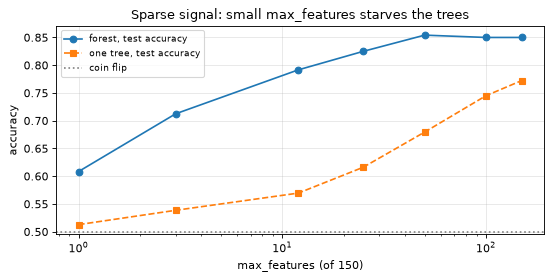

In [17]:
fixes = {
    "RF default (max_features='sqrt' = 12)": RandomForestClassifier(300, random_state=0, n_jobs=-1),
    f"RF with max_features={best_m} (chosen by OOB)": RandomForestClassifier(300, max_features=best_m, random_state=0, n_jobs=-1),
    "select 10 features by mutual information, then RF": make_pipeline(
        SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=0), k=10),
        RandomForestClassifier(300, random_state=0, n_jobs=-1)),
    "gradient boosting (HistGradientBoostingClassifier)": HistGradientBoostingClassifier(random_state=0),
    "logistic regression (linear)": LogisticRegression(max_iter=5000),
    "oracle: RF on x0, x1, x2 only (not available in practice)": None,
}
for name, model in fixes.items():
    if model is None:
        model = RandomForestClassifier(300, random_state=0, n_jobs=-1).fit(Xb_tr[:, :3], yb_tr)
        print(f"{name:58s} test acc {model.score(Xb_te[:, :3], yb_te):.3f}")
        continue
    cv_acc = cross_val_score(model, Xb_tr, yb_tr, cv=5).mean()
    print(f"{name:58s} CV acc {cv_acc:.3f}   test acc {model.fit(Xb_tr, yb_tr).score(Xb_te, yb_te):.3f}")
selected = fixes["select 10 features by mutual information, then RF"][0].get_support().nonzero()[0]
print("features kept by the selector:", selected)

a = np.array(acc_rows)
plt.figure(figsize=(7, 3.6))
plt.plot(a[:, 0], a[:, 2], "o-", label="forest, test accuracy")
plt.plot(a[:, 0], a[:, 3], "s--", label="one tree, test accuracy")
plt.axhline(0.5, color="gray", ls=":", label="coin flip")
plt.xscale("log"); plt.xlabel("max_features (of 150)"); plt.ylabel("accuracy"); plt.legend(fontsize=8)
plt.title("Sparse signal: small max_features starves the trees")
plt.tight_layout(); plt.show()

> **How to read this**
> * With the default 12 candidates, a split sees at least one relevant feature only **22.3 %** of the time
>   (2.0 % at m = 1, 70.7 % at m = 50): about 4 splits in 5 are made between noise features.
> * Forest test accuracy: 0.608 (m = 1), 0.792 (m = 12, default), 0.854 (m = 50), 0.850 (m = 150). One tree on
>   average: 0.513 → 0.570 → 0.679 → 0.772. At small m each tree is barely better than a coin flip. Averaging still
>   helps a lot (one tree 0.570 → forest 0.792 at m = 12: the weak trees' mistakes partly cancel), but it cannot make
>   up for trees that rarely see a relevant feature — the rest of the gap closes only as each tree gets better
>   (contrast with Lab 6, where small m helped).
> * Fixes (CV accuracy on the training set / test accuracy): default 0.795 / 0.792; `max_features=100` chosen by OOB
>   0.861 / 0.850; selecting 10 features by mutual information, then RF 0.864 / 0.858 (it keeps x0, x1, x2 plus 7 noise
>   features); gradient boosting 0.859 / 0.871. The oracle that knows the 3 features reaches 0.875. Logistic
>   regression (0.571 / 0.575) fails because the signal is non-linear (sine, square, step).
> * The selector sits **inside** the pipeline, so `cross_val_score` re-selects on each training fold; selecting on
>   all the data first would leak the labels of the validation rows into the choice of features.

## Lab 12 · A smooth linear target (the old notes' `make_regression` example)

**Goal:** the old notebook trained a forest on `make_regression` (a target that is an exact **linear** function of
10 features plus tiny noise) and reported MSE ≈ 7365 without comment. Put that number next to a straight-line model.

random forest (default = bagging)                       test MSE    7382.28   R² 0.8066


random forest (max_features=0.8, as in the old notes)   test MSE    7357.21   R² 0.8072
random forest (max_features='sqrt')                     test MSE   10283.80   R² 0.7305
linear regression                                       test MSE       0.01   R² 1.0000
(variance of the test target: 38166)


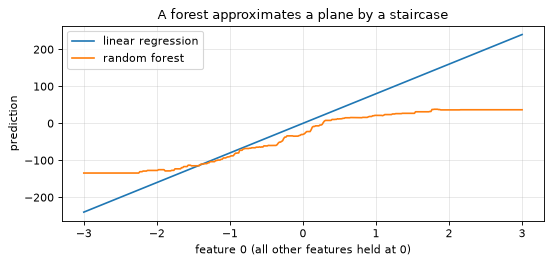

In [18]:
X_lin, y_lin = make_regression(n_samples=1000, n_features=20, n_informative=10, noise=0.1, random_state=42)
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(X_lin, y_lin, test_size=0.3, random_state=42)
for name, model in [("random forest (default = bagging)", RandomForestRegressor(100, random_state=42, n_jobs=-1)),
                    ("random forest (max_features=0.8, as in the old notes)", RandomForestRegressor(100, max_features=0.8, random_state=42, n_jobs=-1)),
                    ("random forest (max_features='sqrt')", RandomForestRegressor(100, max_features="sqrt", random_state=42, n_jobs=-1)),
                    ("linear regression", LinearRegression())]:
    model.fit(Xl_tr, yl_tr)
    print(f"{name:55s} test MSE {mean_squared_error(yl_te, model.predict(Xl_te)):10.2f}   R² {model.score(Xl_te, yl_te):.4f}")
print(f"(variance of the test target: {yl_te.var():.0f})")

x1 = np.linspace(-3, 3, 400)
grid_pts = np.zeros((400, 20)); grid_pts[:, 0] = x1
rf_lin = RandomForestRegressor(100, random_state=42, n_jobs=-1).fit(Xl_tr, yl_tr)
lr_lin = LinearRegression().fit(Xl_tr, yl_tr)
plt.figure(figsize=(7, 3.4))
plt.plot(x1, lr_lin.predict(grid_pts), label="linear regression")
plt.plot(x1, rf_lin.predict(grid_pts), label="random forest")
plt.xlabel("feature 0 (all other features held at 0)"); plt.ylabel("prediction"); plt.legend()
plt.title("A forest approximates a plane by a staircase")
plt.tight_layout(); plt.show()

> **How to read this**
> * The forest's test MSE is **7382** (the old notes printed 7365 with an older scikit-learn; with
>   `max_features=0.8` 7357 vs the old 7363) — about 19 % of the target's variance 38166 (R² 0.81). With `'sqrt'` it
>   is worse (10284): each split sees fewer of the 10 relevant features.
> * A straight line gets MSE **0.01** (R² 1.0000) — the target *is* a weighted sum of the features plus noise with
>   s.d. 0.1.
> * The picture explains it: a forest builds a slope out of steps and flattens at the edges of the data. To
>   approximate a tilted plane in 10 directions at once it needs enormous numbers of splits and rows. For smooth,
>   additive or linear relationships use a linear model (or add one: e.g. fit a linear model, then a forest on its
>   residuals).

## Lab 13 · Extrapolation: a forest cannot predict outside the training range

**Goal:** a short reminder (the long version is in the bagging lab): every tree predicts an average of training
targets, so the forest's prediction is always inside the range of `y` it has seen.

largest training target 10.32;  forest prediction at x=8: 9.83;  truth 16.00;  linear model: 15.95


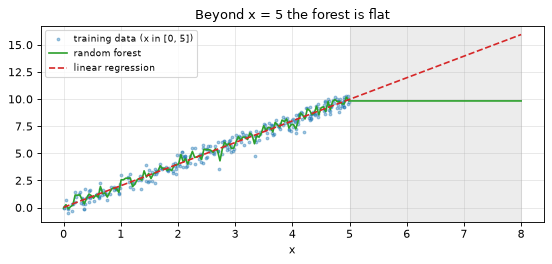

In [19]:
rng = np.random.default_rng(0)
x_tr = rng.uniform(0, 5, 300); y_tr_line = 2 * x_tr + rng.normal(0, 0.5, 300)
x_new = np.linspace(0, 8, 200)
rf_line = RandomForestRegressor(200, random_state=0, n_jobs=-1).fit(x_tr[:, None], y_tr_line)
lin_line = LinearRegression().fit(x_tr[:, None], y_tr_line)
print(f"largest training target {y_tr_line.max():.2f};  forest prediction at x=8: {rf_line.predict([[8.0]])[0]:.2f};"
      f"  truth 16.00;  linear model: {lin_line.predict([[8.0]])[0]:.2f}")
plt.figure(figsize=(7, 3.4))
plt.scatter(x_tr, y_tr_line, s=6, alpha=0.4, label="training data (x in [0, 5])")
plt.plot(x_new, rf_line.predict(x_new[:, None]), color="tab:green", label="random forest")
plt.plot(x_new, lin_line.predict(x_new[:, None]), color="tab:red", ls="--", label="linear regression")
plt.axvspan(5, 8, color="gray", alpha=0.15); plt.legend(fontsize=8); plt.xlabel("x")
plt.title("Beyond x = 5 the forest is flat")
plt.tight_layout(); plt.show()

> **How to read this**
> * The largest training target is 10.32; the forest predicts 9.83 at x = 8, where the truth is 16.00 (the linear
>   model: 15.95). Every leaf stores an average of training targets, so beyond the training range the forest is flat.
>   The bagging notes cover this in depth ([`../../02-bagging/README.md`](../../02-bagging/README.md)).

## Lab 14 · Misleading impurity importance (MDI) and the fix: permutation importance on held-out data

**Goal:** MDI is computed on the **training** data, and a deep tree can always find a "useful-looking" split on a
feature with many distinct values — even pure noise. Build a dataset with two real features of **low cardinality**
(a 0/1 feature and a 4-level feature) and two pure-noise features (one continuous with ~1000 distinct values, one 0/1).

min_samples_leaf=1: train acc 1.000, test acc 0.687
   real 0/1          MDI 0.321   permutation (test) +0.173 ± 0.020
   real 4-level      MDI 0.105   permutation (test) +0.028 ± 0.015
   NOISE continuous  MDI 0.557   permutation (test) +0.006 ± 0.022
   NOISE 0/1         MDI 0.018   permutation (test) -0.010 ± 0.016


min_samples_leaf=20: train acc 0.801, test acc 0.757
   real 0/1          MDI 0.708   permutation (test) +0.235 ± 0.023
   real 4-level      MDI 0.184   permutation (test) +0.021 ± 0.009
   NOISE continuous  MDI 0.098   permutation (test) -0.004 ± 0.012
   NOISE 0/1         MDI 0.009   permutation (test) -0.002 ± 0.002


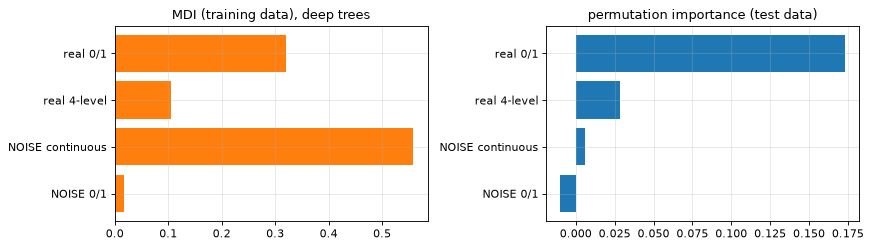

In [20]:
rng = np.random.default_rng(0)
n = 1000
x_bin, x_cat = rng.integers(0, 2, n), rng.integers(0, 4, n)
noise_cont, noise_bin = np.round(rng.normal(size=n), 4), rng.integers(0, 2, n)
logit = 3 * (x_bin - 0.5) + 0.8 * (x_cat - 1.5)
y_imp = (rng.uniform(size=n) < 1 / (1 + np.exp(-logit))).astype(int)
X_imp = np.column_stack([x_bin, x_cat, noise_cont, noise_bin]).astype(float)
names = ["real 0/1", "real 4-level", "NOISE continuous", "NOISE 0/1"]
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(X_imp, y_imp, test_size=0.3, random_state=0)

for leaf in [1, 20]:                                                 # <- deep trees vs regularised trees
    f = RandomForestClassifier(200, min_samples_leaf=leaf, random_state=0, n_jobs=-1).fit(Xi_tr, yi_tr)
    perm = permutation_importance(f, Xi_te, yi_te, n_repeats=20, random_state=0, n_jobs=-1)
    print(f"min_samples_leaf={leaf}: train acc {f.score(Xi_tr, yi_tr):.3f}, test acc {f.score(Xi_te, yi_te):.3f}")
    for j, name in enumerate(names):
        print(f"   {name:17s} MDI {f.feature_importances_[j]:.3f}   permutation (test) "
              f"{perm.importances_mean[j]:+.3f} ± {perm.importances_std[j]:.3f}")
    if leaf == 1:
        mdi_deep, perm_deep = f.feature_importances_, perm.importances_mean

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].barh(names, mdi_deep, color="tab:orange"); axes[0].set_title("MDI (training data), deep trees")
axes[1].barh(names, perm_deep, color="tab:blue"); axes[1].set_title("permutation importance (test data)")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout(); plt.show()

> **How to read this**
> * Deep trees: MDI ranks the **pure-noise continuous feature first (0.557)**, above the real 0/1 feature (0.321).
>   Permutation importance on the test set puts things right: real 0/1 +0.173, real 4-level +0.028, noise continuous
>   +0.006 ± 0.022 (zero within its noise), noise 0/1 −0.010.
> * Why: MDI is measured on the **training** rows, which deep trees memorise (train accuracy 1.000, test 0.687). Deep
>   in a tree, a feature with ~1000 distinct values offers hundreds of thresholds to isolate a few rows, and every such
>   split "reduces impurity" on training data. A 0/1 feature offers one threshold.
> * With `min_samples_leaf=20` the noise feature's MDI falls to 0.098 and test accuracy rises to 0.757; permutation
>   importance gives the same verdict in both settings.
> * Rule: use MDI as a quick look; for decisions use permutation importance on held-out data (or drop-column
>   importance).

## Lab 15 · Correlated features share (or hide) the credit

**Goal:** on the good-fit data all 31 features measure the same thing. How do bagging and the random forest split
the credit, and what happens to permutation importance when a feature has near-copies?

MDI of x0 (the precise thermometer): bagging 0.829, random forest 0.168
mean MDI of one cheap thermometer : bagging 0.006, random forest 0.028


permutation importance (drop in test R²) of x0: 0.085; of a cheap one on average: 0.007
sum of the 31 single-feature permutation importances: 0.308  vs  permuting all 31 together: 1.719


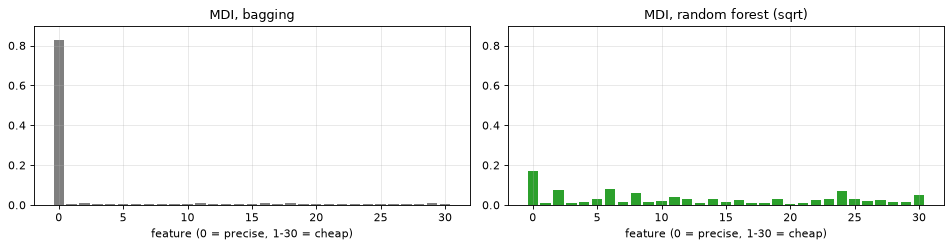

In [21]:
bag_good = contenders["bagging (max_features=1.0, the regressor default)"]
print(f"MDI of x0 (the precise thermometer): bagging {bag_good.feature_importances_[0]:.3f}, "
      f"random forest {rf_good.feature_importances_[0]:.3f}")
print(f"mean MDI of one cheap thermometer : bagging {bag_good.feature_importances_[1:].mean():.3f}, "
      f"random forest {rf_good.feature_importances_[1:].mean():.3f}")

perm_rf = permutation_importance(rf_good, Xg_te, yg_te, n_repeats=10, random_state=0, n_jobs=-1)
print(f"permutation importance (drop in test R²) of x0: {perm_rf.importances_mean[0]:.3f}; "
      f"of a cheap one on average: {perm_rf.importances_mean[1:].mean():.3f}")

# permute ALL 31 thermometers together = the importance of the shared signal
rng = np.random.default_rng(0)
base = r2_score(yg_te, rf_good.predict(Xg_te))
shuffled = Xg_te[rng.permutation(len(Xg_te))]
group = base - r2_score(yg_te, rf_good.predict(shuffled))
print(f"sum of the 31 single-feature permutation importances: {perm_rf.importances_mean.sum():.3f}  vs  "
      f"permuting all 31 together: {group:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].bar(range(31), bag_good.feature_importances_, color="tab:gray"); axes[0].set_title("MDI, bagging")
axes[1].bar(range(31), rf_good.feature_importances_, color="tab:green"); axes[1].set_title("MDI, random forest (sqrt)")
for ax in axes:
    ax.set_xlabel("feature (0 = precise, 1-30 = cheap)"); ax.set_ylim(0, 0.9)
plt.tight_layout(); plt.show()

> **How to read this**
> * MDI of x0: bagging **0.829**, random forest **0.168**; a cheap thermometer gets 0.006 vs 0.028 on average.
>   Neither is "the truth" — all 31 measure the same z. Bagging hands the credit to whichever feature wins the top
>   splits; the forest spreads it (that is the decorrelation of Lab 3, seen through importances).
> * Permutation importance hides correlated features the other way: shuffling x0 costs only 0.085 of R², a cheap one
>   0.007, all 31 together sum to 0.308 — but **shuffling all 31 at once costs 1.719** (R² from 0.940 to below 0).
>   Each thermometer alone looks unimportant because the other 30 still carry z.
> * Fix: group strongly correlated features (here: all 31) and permute or drop the group; report the group's
>   importance.

## Lab 16 · Size and speed of deep forests

**Goal:** fully grown trees have roughly one leaf per distinct training row, so a forest's memory grows like
`n_estimators × n_rows`. Measure node counts, bytes and prediction time, and see how `min_samples_leaf` shrinks them.

In [22]:
def forest_bytes(forest):
    """Bytes of the node arrays + value arrays of all trees (what dominates a saved forest)."""
    total = 0
    for est in forest.estimators_:
        state = est.tree_.__getstate__()
        total += state["nodes"].nbytes + state["values"].nbytes
    return total


X_big, y_big = make_good_fit(seed=5, n=20000)
one_row = X_big[:1]
print(f"{'model':38s} nodes/tree   size MB   predict 1 row (ms)   predict 5000 rows (ms)")
for leaf in [1, 5, 50]:
    f = RandomForestRegressor(100, max_features="sqrt", min_samples_leaf=leaf, random_state=0, n_jobs=-1).fit(X_big, y_big)
    f.set_params(n_jobs=1)
    t0 = time.perf_counter(); [f.predict(one_row) for _ in range(20)]; t1 = (time.perf_counter() - t0) / 20 * 1e3
    t0 = time.perf_counter(); f.predict(X_big[:5000]); t2 = (time.perf_counter() - t0) * 1e3
    print(f"{'RF 100 trees, min_samples_leaf=' + str(leaf):38s} {np.mean([e.tree_.node_count for e in f.estimators_]):9.0f}"
          f"   {forest_bytes(f) / 1e6:7.1f}   {t1:12.2f}          {t2:12.1f}")
lin = LinearRegression().fit(X_big, y_big)
t0 = time.perf_counter(); [lin.predict(one_row) for _ in range(20)]; t1 = (time.perf_counter() - t0) / 20 * 1e3
print(f"{'linear regression':38s} {'-':>9s}   {(lin.coef_.nbytes + 8) / 1e6:7.4f}   {t1:12.2f}")

model                                  nodes/tree   size MB   predict 1 row (ms)   predict 5000 rows (ms)


RF 100 trees, min_samples_leaf=1           24409     175.7           2.36                  92.7


RF 100 trees, min_samples_leaf=5            4056      29.2           2.29                  47.4


RF 100 trees, min_samples_leaf=50            385       2.8           2.37                  27.8
linear regression                              -    0.0003           0.04


> **How to read this**
> * With 20,000 rows a fully grown tree has 24,409 nodes (≈ 2 × the distinct rows it saw) and 100 trees take
>   **176 MB**. `min_samples_leaf=5` cuts that to 29 MB, `50` to 2.8 MB.
> * Predicting one row takes about 2.3 ms whatever the size (per-call overhead dominates) vs ≈ 0.04 ms for a linear
>   model; for 5,000 rows the deep forest needs ≈ 90 ms, the most pruned one ≈ 28 ms (timings vary between runs).
> * Memory grows like `n_estimators × n_rows`: at a million rows, 100 deep trees need about 9 GB (from-scratch
>   notebook §8). Fixes: `min_samples_leaf` / `max_depth` / `max_leaf_nodes` (check with CV), fewer trees (Lab 7: 100
>   are as good as 500 here), or a boosted model of small trees.

---
# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| 1 | Var = ρσ² + (1−ρ)σ²/B; the 8-row tree has MDI 0.6 / 0.4 | ✔ formula = simulation (3.208 / 1.535); scikit-learn gives `[0.6, 0.4]` |
| 2 | MDI = weighted impurity decrease, normalised per tree, averaged; the old custom MDI was wrong | ✔ matches to 2e-17; old version off by 0.08 |
| 3 | Per-split sampling beats per-tree sampling; the default regressor is bagging | ✔ 0.299 vs 0.352 vs 0.343; identical predictions |
| 4 | Smaller `max_features`: ρ ↓, σ² ↑, U-shaped error | ✔ ρ 0.404 → 0.268; best m = 8 |
| 5 | RF beats one tree and bagging; its trees are strong, not weak | ✔ 0.703 / 0.342 / 0.299; tree test R² 0.80 |
| 6 | Averaging cuts variance, not bias | ✔ variance 13–40× smaller, bias unchanged |
| 7 | More trees never over-fit; tree size is the real knob | ✔ flat curve; deep trees best here |
| 8 | OOB ≈ CV ≈ test, for free | ✔ 0.935 / 0.933 / 0.940 |
| 9 | Tune with CV or OOB, touch the test set once | ✔ both pick (5, 1); test MSE 0.296 |
| 10 | Median of trees: robust to corrupted targets, not universally better | ✔ 1.027 → 0.263; worse for bagging on Friedman |
| 11 | ✘ Few relevant features among many starve small-`max_features` trees | failure shown (0.792 vs 0.850–0.871 with fixes) |
| 12 | ✘ Smooth linear target | failure shown (MSE 7382 vs 0.01) |
| 13 | ✘ No extrapolation | failure shown (9.83 vs 16) |
| 14 | ✘ MDI favours high-cardinality noise | failure shown (noise MDI 0.557, permutation ≈ 0) |
| 15 | ✘ Correlated features share or hide credit | failure shown (0.829 vs 0.168; 0.308 vs 1.719) |
| 16 | ✘ Deep forests are large | failure shown (176 MB for 100 trees on 20k rows) |